<!-- repo-header -->
# Building the 53-qubit Stage-1 circuit for H2-1

Constructs the Q-MERGE Stage-1 circuit that was actually run on hardware: **M = 4
segments of N = 1024** taken from the middle rows of the upsampled ultrasound
dataset.

    4 preparation registers x 10 qubits  =  40
    storage register                     =  10
    index register (m = log2 M)          =   2
    block-encoding ancilla               =   1
                                          ----
                                            53 qubits

Each `U_prep` is deliberately held to a **single** SSO layer. That is not an
oversight: the point of the experiment is to test the Q-MERGE protocol itself, so
the gate count and the noise should be dominated by the SELECT-SWAP network rather
than by the segment preparation underneath it.

> **Note the filename-to-content mismatch in the original:** this was adapted from a
> 4 x 256 notebook, but `TAG = "4x1024_L1_mid"` and it builds the 4 x 1024 circuit
> reported in the paper.

Writes `mre_qc_4x1024_L1_mid.qpy`, `mre_prep_circuits_4x1024_L1_mid.qpy` and
`mre_target_data_4x1024_L1_mid.npz`, all consumed by
`04_shadow_overlap_and_calibration.ipynb`.


# Multi-register CSWAP compression -- 4x1024 R75, middle rows, 1-layer SSO prep (Stage 1)

Same target-data family as `Multi-register compression (4x32).ipynb`, but:
- **4x upsampled** -- these are 4 of the actual 128 rows of the full R75 image,
  resampled via `skimage.transform.resize` from their native ~256-sample resolution
  up to length 1024, so each register needs n = log2(1024) = 10 qubits instead of 8.
- **1 staircase layer** instead of 10, to minimise gate count for this hardware run
  (expect noticeably lower per-row fidelity than the 4x32 demo -- that's the trade
  being made here, not a bug).

This notebook only does Stage 1 (per-row `U_prep`) and saves the circuits to disk.
Building the SELECT-SWAP compression circuit around them (Sec. 2b onward in the
4x32 notebook) is the next step, once these are checked.

In [1]:
# NOTE: %autoreload is deliberately NOT used here -- on this machine/IPython version
# it triggers a noisy (non-fatal) UnicodeDecodeError from the `deduperreload` extension
# scanning stdlib source files under Windows' cp1252 default encoding, and forcibly
# redirecting stderr to suppress it destabilises the live ipykernel (confirmed: breaks
# its ZMQ heartbeat). Instead: after editing mre_prep.py / sso_rowprep.py, just re-run
# THIS cell (it explicitly importlib.reload()s both) before re-running downstream cells.
import importlib, io, contextlib, warnings
warnings.filterwarnings('ignore')
import numpy as np
import matplotlib.pyplot as plt
import mre_prep as mre
importlib.reload(mre)
# sso_rowprep imports the SSO stack, which prints self-checks on import -- silence them
with contextlib.redirect_stdout(io.StringIO()):
    import sso_rowprep as srp
    importlib.reload(srp)
np.set_printoptions(precision=4, suppress=True)

def show(qc, **kw):
    """Draw with matplotlib; fall back to text if pylatexenc/mpl is unavailable."""
    try:
        return qc.draw('mpl', **kw)
    except Exception as e:
        print(f"(mpl draw unavailable -> text): {e}")
        return qc.draw('text', fold=-1)

## 1. Pick 4 rows from the full (upsampled) R75 data

`Y_full` here is a 1024x128 array -- `resize()` upsamples each row from the raw
excel sheet's native ~256-sample resolution up to length 1024 (4x), via
`anti_aliasing=True` interpolation, not real additional data. Row `i` is
`Y_full[:, i]`, length N=1024, so n=log2(1024)=10 qubits per register.

`ROW_IDX` picks which 4 of the 128 rows to use -- currently the middle 4. Change
this list to pick a different/more "interesting" set of rows (e.g. by IPR, by
peak amplitude, or just eyeballing the full-R75 image from the diagrams notebook).

picked rows [62, 63, 64, 65] from the full 128-row R75 data -> 4 chunks of length 1024 (n=10 qubits each)


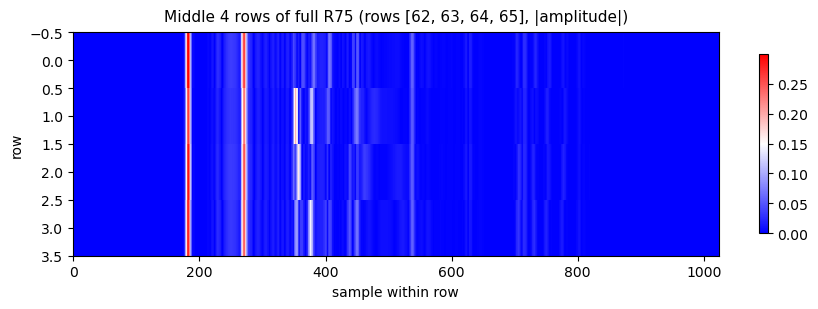

In [2]:
import pandas as pd
from skimage.transform import resize

FULL_M, FULL_N = 128, 1024                 # the full R75 dataset's shape (registers, samples/register)
df = pd.read_excel('R75 Ultrasound data.xlsx', header=None)
Y_full = resize(df.to_numpy(), (FULL_N, FULL_M), anti_aliasing=True)   # (1024, 128) -- 4x upsampled from native
Y_full = Y_full / np.linalg.norm(Y_full)

ROW_IDX = [62, 63, 64, 65]                  # the "middle 4" of 128 rows -- edit to pick a different 4
M, N = len(ROW_IDX), FULL_N                 # M=4 registers, N=1024 samples/register -> n=10 qubits/register
n = int(np.log2(N))

chunks = [Y_full[:, i].astype(complex) / np.linalg.norm(Y_full[:, i]) for i in ROW_IDX]
print(f"picked rows {ROW_IDX} from the full {FULL_M}-row R75 data "
      f"-> {M} chunks of length {N} (n={n} qubits each)")

img = np.abs(np.stack(chunks))                                        # (4 rows, 1024 samples)
fig, ax = plt.subplots(figsize=(9, 3.2))
im = ax.imshow(img, aspect='auto', cmap='bwr', interpolation='nearest', vmin=img.min(), vmax=img.max())
ax.set_title(f'Middle 4 rows of full R75 (rows {ROW_IDX}, |amplitude|)', fontsize=11, pad=8)
ax.set_xlabel('sample within row'); ax.set_ylabel('row')
fig.colorbar(im, ax=ax, shrink=0.8)
plt.tight_layout()
plt.show()

## 2. SSO staircase row preparation (1 chi=2 layer)

Same call as the 4x32 notebook's Sec. 2, just `num_layers=1` -- one staircase layer
of 2-qubit SU(4) gates plus the analytic chi=2 residual prep, per row. This is the
single classical-optimisation step; expect it to run in well under a minute given
only 4 rows x 1 layer.

In [3]:
prep_circuits, fids = srp.build_prep_circuits(chunks, chi=2, num_layers=1, n_iter=200)
prodF = float(np.prod(fids))
print(f"\nprod_i F_i = {prodF:.10f}   (combined infidelity {1 - prodF:.2e})")
print(f"one row prep: {prep_circuits[0].num_qubits} qubits, {prep_circuits[0].size()} staircase gates")

  row 0: SSO final fid = 0.8985790360   (infidelity 1.01e-01)
  row 1: SSO final fid = 0.8454400890   (infidelity 1.55e-01)
  row 2: SSO final fid = 0.9059203974   (infidelity 9.41e-02)
  row 3: SSO final fid = 0.8655285128   (infidelity 1.34e-01)

prod_i F_i = 0.5956765959   (combined infidelity 4.04e-01)
one row prep: 10 qubits, 20 staircase gates


### 2a. The staircase for one row

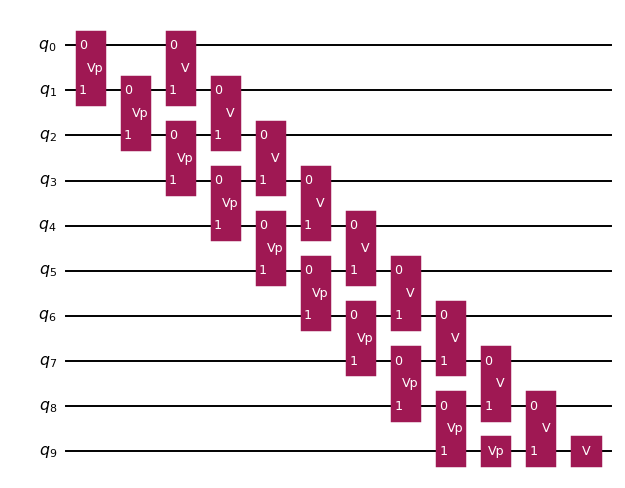

In [4]:
show(prep_circuits[0], fold=-1, scale=0.7)

### 2b. Per-row prep check

`Statevector(prep_i)` vs the target row should equal the reported SSO fidelity `F_i`.
With only 1 layer, expect these fidelities to be noticeably lower than the 4x32
(10-layer) demo -- that's the expected cost of the reduced gate count, not a bug.

In [5]:
from qiskit.quantum_info import Statevector
for i, row in enumerate(ROW_IDX):
    f = mre.fidelity(np.asarray(Statevector(prep_circuits[i])), chunks[i])
    print(f"row {row}: fidelity(prep|0>, row) = {f:.6f}   (reported F_i = {fids[i]:.6f})")

row 62: fidelity(prep|0>, row) = 0.898579   (reported F_i = 0.898579)
row 63: fidelity(prep|0>, row) = 0.845440   (reported F_i = 0.845440)
row 64: fidelity(prep|0>, row) = 0.905920   (reported F_i = 0.905920)
row 65: fidelity(prep|0>, row) = 0.865529   (reported F_i = 0.865529)


## 3. Build the compression circuit (SSO prep composed in)

Same call as the 4x32 notebook's Sec. 3: registers **S, I, A_0..A_3, anc** (low->high),
each `A_i` gets the SSO staircase composed in, then `S`,`I` go into superposition, then
the SELECT-SWAPs use the paper's **Fig. 2 decomposition** (2 C^mNOT + n CSWAP + one
zeroed ancilla).

The only thing that changes from the 4x32 case is `n` (10 instead of 5), which is picked
up automatically from `prep_circuits[0].num_qubits` -- but it changes the qubit total a
lot: `M*n + n + m + anc = 4*10 + 10 + 2 + 1 = 53` qubits, vs. 28 before. That's the number
that matters for what we can and can't do next (see the note after the TKET cell).

Circuit drawing is skipped here (not just simulation) -- a 53-qubit, 4-register circuit
diagram is unwieldy to render/read; the qubit/depth/gate counts below are what actually
matter at this stage.

In [6]:
qc, layout = mre.build_compression_circuit(chunks, prep_circuits=prep_circuits,
                                           decomposed=True, barrier=True)
print(f"qubits = {qc.num_qubits}  (S={layout['n']}, I={layout['m']}, "
      f"{M}xA={M*layout['n']}, anc=1)")
print(f"depth  = {qc.depth()}   gates = {qc.size()}")

qubits = 53  (S=10, I=2, 4xA=40, anc=1)
depth  = 60   gates = 140


### TKET decomposition

Same as the 4x32 notebook's TKET cell, unchanged -- compile to H2-1's native gate set
(PhasedX, Rz, ZZPhase) at `optimisation_level=2`. This is the real depth/gate-count number
that determines whether this fits H2-1's error budget, independent of whether we can
*simulate* it classically.

In [7]:
from pytket.extensions.quantinuum import QuantinuumBackend
from pytket.extensions.qiskit import qiskit_to_tk

tk_circ = qiskit_to_tk(qc)

backend = QuantinuumBackend("H2-1")

compiled = backend.get_compiled_circuit(
    tk_circ,
    optimisation_level=2
)
from pytket.extensions.qiskit import tk_to_qiskit

qiskit_compiled = tk_to_qiskit(compiled)

print(f"compiled depth = {compiled.depth()}   n_gates = {compiled.n_gates}")

compiled depth = 381   n_gates = 1532


In [8]:
from collections import Counter

gate_counts = Counter(cmd.op.type.name for cmd in compiled)
print(gate_counts)

Counter({'PhasedX': 941, 'ZZPhase': 496, 'Rz': 94, 'Barrier': 1})


## 4-5. Full statevector smoke test / decomposed-vs-logical cross-check -- SKIPPED

The 4x32 notebook's Sec. 4 (`mre.simulate_statevector(qc)`, a full dense statevector) and
Sec. 5 (rebuild with `decomposed=False` and compare) both simulate the *entire* circuit.
At 28 qubits that was 4.3 GB -- fine. At **53 qubits it's `2**53` complex128 amplitudes,
~144 PB** -- not fine, on any machine. This is the qubit-count wall flagged earlier, now
concrete.

Skipping these doesn't leave correctness unchecked, though -- both things they verify are
**structural, not data-dependent**:
- The SELECT-SWAP decomposition (Fig. 2: 2 C^mNOT + n CSWAP + 1 ancilla) implements the
  same unitary as the undecomposed m-controlled swaps for *any* n -- that's a circuit
  identity, already confirmed exactly in the 4x32 notebook (Sec. 5, fidelity 1.0 to
  machine precision), and it doesn't depend on n.
- The compression itself is exact (Eq. 5: reconstruction fidelity = `prod_i F_i`) by the
  same n-independent argument -- it only depends on `M` (number of branches), not `n`.

So there's nothing new to re-derive at n=10; the previous 4x32 run already is the proof.
If you still want a live numerical check at this scale, the options are:
1. **Small-n dry run** -- rebuild `build_compression_circuit` with the *same* M=4 but
   short random chunks (e.g. n=3) purely to re-exercise the code path end-to-end; cheap,
   but doesn't touch these specific rows' fidelities.
2. **Per-branch marginal check** -- exploit the same Eq. 5 projection used in the
   shadow-overlap notebook (conditioning on the index register leaves each branch's
   storage register in `prep_circuits[i]`'s own small statevector) to verify one branch
   at a time on an n-qubit simulator, without ever building the full 2**53-amplitude
   state.

## 8. Save circuits for the shadow-overlap notebook

Same as the 4x32 notebook's Sec. 8: serialises `qc` and `prep_circuits` via **QPY**
(lossless for the `unitary(...)`-based gates this uses; QASM can't represent them
exactly). No `qc_direct` here -- the direct chi=2 baseline (old Sec. 6) wasn't built
for this run, since it wasn't asked for; add it later the same way if you want the
Fig. 4/6-style comparison for this dataset too.

Distinct filenames from the 4x32 demo's (`mre_qc.qpy` / `mre_prep_circuits.qpy` /
`mre_target_data.npz`) so this run doesn't clobber that one -- both sets live in the
folder side by side. `TAG` describes the run: 4 registers x 1024-length, 1 staircase
layer, middle rows.

In [9]:
from qiskit import qpy

TAG = "4x1024_L1_mid"   # 4 registers x 1024-length rows, 1 staircase layer, middle-4 rows

with open(f'mre_qc_{TAG}.qpy', 'wb') as f:
    qpy.dump([qc], f)
with open(f'mre_prep_circuits_{TAG}.qpy', 'wb') as f:
    qpy.dump(prep_circuits, f)

np.savez(f'mre_target_data_{TAG}.npz', chunks=np.stack(chunks), row_idx=np.array(ROW_IDX),
         M=M, N=N, n=n, fids=np.array(fids), total_qubits=qc.num_qubits)
print(f"saved: mre_qc_{TAG}.qpy, mre_prep_circuits_{TAG}.qpy, mre_target_data_{TAG}.npz")

saved: mre_qc_4x1024_L1_mid.qpy, mre_prep_circuits_4x1024_L1_mid.qpy, mre_target_data_4x1024_L1_mid.npz


### 8a. Round-trip check

Only checking the prep circuits' round-trip via full simulation (cheap, 10 qubits each).
`qc` itself is 53 qubits -- round-tripping it the same way the 4x32 notebook does
(`simulate_statevector` before/after) hits the same wall as Sec. 4-5 above, so instead
we just confirm the QPY load reproduces an identical circuit structurally (same gates,
same registers), which is what actually matters for "does the saved file replay the same
circuit" -- the numerics were already checked when `qc` was built from these exact
`prep_circuits` in Sec. 3.

In [10]:
with open(f'mre_prep_circuits_{TAG}.qpy', 'rb') as f:
    prep_circuits_check = qpy.load(f)
for i, row in enumerate(ROW_IDX):
    sv_a = mre.simulate_statevector(prep_circuits[i])
    sv_b = mre.simulate_statevector(prep_circuits_check[i])
    print(f"row {row} round-trip fidelity = {mre.fidelity(sv_a, sv_b):.12f}")

with open(f'mre_qc_{TAG}.qpy', 'rb') as f:
    qc_check = qpy.load(f)[0]
print(f"\nqc round-trip: {qc_check.num_qubits} qubits, {qc_check.size()} gates, "
      f"depth {qc_check.depth()}   (matches original: "
      f"{qc_check.num_qubits == qc.num_qubits and qc_check.size() == qc.size() and qc_check.depth() == qc.depth()})")

row 62 round-trip fidelity = 1.000000000000
row 63 round-trip fidelity = 1.000000000000
row 64 round-trip fidelity = 1.000000000000
row 65 round-trip fidelity = 1.000000000000

qc round-trip: 53 qubits, 140 gates, depth 60   (matches original: True)


### Load cell -- paste this into the shadow-overlap notebook for this dataset

Keep `mre_qc_4x1024_L1_mid.qpy`, `mre_prep_circuits_4x1024_L1_mid.qpy`, and
`mre_target_data_4x1024_L1_mid.npz` in the same `MultiRegister Encoding/` folder.

```python
import numpy as np
from qiskit import qpy

TAG = "4x1024_L1_mid"
with open(f'mre_qc_{TAG}.qpy', 'rb') as f:
    qc = qpy.load(f)[0]
with open(f'mre_prep_circuits_{TAG}.qpy', 'rb') as f:
    prep_circuits = qpy.load(f)

data = np.load(f'mre_target_data_{TAG}.npz')
chunks = list(data['chunks'])       # 4 row vectors, chunks[i].shape == (1024,)
row_idx = data['row_idx']; M = int(data['M']); N = int(data['N']); n = int(data['n'])
fids = data['fids']

print(f"qc: {qc.num_qubits}q   {len(prep_circuits)} prep circuits, {prep_circuits[0].num_qubits}q each   "
      f"rows={list(row_idx)}   chunks: {len(chunks)}x{chunks[0].shape}")
```